# Random Forest — SHAP Error Analysis

This notebook examines the classification errors of the official Random Forest baseline using SHAP (SHapley Additive exPlanations). The analysis focuses on **62 false positives**, in which legitimate emails were classified as phishing, and **15 false negatives**, in which phishing emails were classified as legitimate.

The baseline model, TF-IDF vectorizer, data split, and recorded predictions remain unchanged. SHAP is used to examine the contribution of individual features to the model's predictions. **No model retraining or TF-IDF refitting takes place in this notebook.**

### Reproducibility

The analysis uses the saved baseline checkpoint produced by the preceding Random Forest notebook. To reproduce the calculations, run the cells in order in Google Colab with access to the original checkpoint files. The notebook checks the dataset dimensions, confusion matrix, prediction hash, SHAP version, and explanation consistency before presenting the results.

The tables report values from the original experiment. The horizontal SHAP feature-importance figure is included below so that it is visible when the notebook is viewed on GitHub. Running its plotting cell reproduces the figure from the recorded values.


## 1. Load and verify the official baseline

This analysis uses the saved Random Forest model, TF-IDF vectorizer, feature matrices, labels, and predictions from **RF 02 — Official Baseline**. These files are checked before the SHAP analysis begins so that the results can be traced to the original experiment.

The required checkpoint files must be available in the working environment. They can be stored locally when using Jupyter Notebook or in the user's own workspace when using Google Colab. Neither the classifier nor the TF-IDF vectorizer is fitted again in this notebook.


In [ ]:
import hashlib
import os
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import confusion_matrix

# Use the checkpoint exported by RF 02. This works in Jupyter Notebook
# or Google Colab when the checkpoint files are accessible locally.
# Set RF_BASELINE_DIR to a different folder if needed.
checkpoint_override = os.environ.get('RF_BASELINE_DIR')
if checkpoint_override:
    BASELINE_DIR = Path(checkpoint_override).expanduser()
else:
    checkpoint_candidates = [
        Path('Official_Random_Forest_Baseline'),
        Path('random_forest/Official_Random_Forest_Baseline'),
        Path('random_forest/results/Official_Random_Forest_Baseline'),
        Path('../Official_Random_Forest_Baseline'),
        Path('../../Official_Random_Forest_Baseline'),
    ]
    BASELINE_DIR = next(
        (path for path in checkpoint_candidates if path.is_dir()),
        checkpoint_candidates[0],
    )

if not BASELINE_DIR.is_dir():
    raise FileNotFoundError(
        f'Random Forest baseline checkpoint not found: {BASELINE_DIR}. '
        'Run RF 02 to generate the checkpoint and place its output in an '
        'accessible folder, or set the RF_BASELINE_DIR environment variable '
        'to the folder containing the saved checkpoint files.'
    )

print('Official baseline directory:', BASELINE_DIR.resolve())
print('Available checkpoint files:', sorted(p.name for p in BASELINE_DIR.iterdir()))


In [ ]:
# Restore the official RF 02 checkpoint, using the exact filenames saved by
# the baseline notebook. No model retraining or TF-IDF refitting.
import json
from scipy import sparse

checkpoint_files = {
    'rf_baseline_model.joblib': 'model',
    'tfidf_vectorizer.joblib': 'vectorizer',
    'X_train_tfidf.npz': 'train matrix',
    'X_test_tfidf.npz': 'test matrix',
    'y_train.npy': 'training labels',
    'y_test.npy': 'test labels',
    'baseline_predictions.npy': 'baseline predictions',
    'baseline_probabilities.npy': 'baseline probabilities',
    'baseline_manifest.json': 'manifest',
}
missing_files = [name for name in checkpoint_files if not (BASELINE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        'The RF 02 checkpoint is missing these files: ' + ', '.join(missing_files) +
        '. Run the checkpoint export in RF 02, or use the original baseline '
        'recovery code if your existing Drive files have different names.'
    )

rf_model = joblib.load(BASELINE_DIR / 'rf_baseline_model.joblib')
tfidf_vectorizer = joblib.load(BASELINE_DIR / 'tfidf_vectorizer.joblib')
X_train_tfidf = sparse.load_npz(BASELINE_DIR / 'X_train_tfidf.npz')
X_test_tfidf = sparse.load_npz(BASELINE_DIR / 'X_test_tfidf.npz')
y_train = np.load(BASELINE_DIR / 'y_train.npy', allow_pickle=False).reshape(-1).astype(int)
y_test = np.load(BASELINE_DIR / 'y_test.npy', allow_pickle=False).reshape(-1).astype(int)
baseline_pred_rf = np.load(BASELINE_DIR / 'baseline_predictions.npy', allow_pickle=False).reshape(-1).astype(int)
baseline_prob_rf = np.load(BASELINE_DIR / 'baseline_probabilities.npy', allow_pickle=False).reshape(-1)
with open(BASELINE_DIR / 'baseline_manifest.json', encoding='utf-8') as f:
    baseline_manifest_rf = json.load(f)

assert X_train_tfidf.shape == (42861, 10000)
assert X_test_tfidf.shape == (10716, 10000)
assert len(y_train) == 42861 and len(y_test) == 10716
assert len(baseline_pred_rf) == 10716 and len(baseline_prob_rf) == 10716
assert len(rf_model.estimators_) == 100
assert np.array_equal(confusion_matrix(y_test, baseline_pred_rf, labels=[0, 1]), [[4686, 62], [15, 5953]])
assert baseline_manifest_rf['confusion_matrix_sklearn'] == [[4686, 62], [15, 5953]]
actual_hash = hashlib.sha256(np.ascontiguousarray(baseline_pred_rf).tobytes()).hexdigest()
assert actual_hash == baseline_manifest_rf['predictions_sha256']
assert actual_hash == '2c7f695b0dfae480ae17a5e59bb661b4e76606d45dc7e30bf2e8f0c74230cc2e'
false_positive_positions_rf = np.flatnonzero((y_test == 0) & (baseline_pred_rf == 1))
false_negative_positions_rf = np.flatnonzero((y_test == 1) & (baseline_pred_rf == 0))
assert len(false_positive_positions_rf) == 62
assert len(false_negative_positions_rf) == 15
print('Official RF baseline checkpoint verified: 62 FP and 15 FN.')
print('Prediction SHA-256:', actual_hash)


### Baseline classification results

| Email class | Correctly classified | Incorrectly classified |
|---|---:|---:|
| Legitimate (class 0) | 4,686 | 62 false positives |
| Phishing (class 1) | 5,953 | 15 false negatives |

The baseline produced **77 classification errors**. All 62 false positives and 15 false negatives are included in the SHAP analysis.


## 2. SHAP configuration

The original analysis used **SHAP 0.52.0** with **NumPy 2.1.3**. A background sample of 100 training emails was selected, comprising 50 legitimate and 50 phishing emails. The sample was selected using `np.random.default_rng(42)` to retain the original experimental setting.

The Random Forest is explained using the interventional TreeExplainer with probability output. All SHAP values reported in this notebook refer to the phishing class (class 1). The same background sample is used for both false-positive and false-negative analyses.


In [ ]:
# Use in the intended Colab environment, if SHAP is not installed:
# %pip install shap==0.52.0
import shap
print('SHAP:', shap.__version__, 'NumPy:', np.__version__)
assert shap.__version__ == '0.52.0', 'Use the recorded SHAP version for strict reproduction.'

rng = np.random.default_rng(42)
legit_idx = np.flatnonzero(y_train == 0)
phish_idx = np.flatnonzero(y_train == 1)
background_indices = np.concatenate([rng.choice(legit_idx, 50, replace=False), rng.choice(phish_idx, 50, replace=False)])
X_background_step8 = X_train_tfidf[background_indices].toarray()
assert X_background_step8.shape == (100, 10000)

explainer_rf = shap.TreeExplainer(rf_model, data=X_background_step8, feature_perturbation='interventional', model_output='probability')
print('Expected values:', explainer_rf.expected_value)

## 3. False-positive SHAP analysis

False positives occur when legitimate emails are incorrectly classified as phishing. SHAP is applied to all **62 false-positive cases** to examine the contribution of individual TF-IDF features to these predictions.

Positive SHAP values increase the predicted phishing probability, while negative values reduce it.


In [ ]:
def phishing_class_shap(values):
    if isinstance(values, list) and len(values) == 2:
        return np.asarray(values[1])
    arr = np.asarray(values)
    if arr.ndim == 3 and arr.shape[-1] == 2:
        return arr[:, :, 1]
    if arr.ndim == 2:
        return arr
    raise ValueError(f'Unexpected SHAP output shape: {arr.shape}')

fp_tfidf_rf = X_test_tfidf[false_positive_positions_rf]
fp_parts = []
for start in range(0, len(false_positive_positions_rf), 5):
    dense = fp_tfidf_rf[start:start+5].toarray()
    fp_parts.append(phishing_class_shap(explainer_rf.shap_values(dense, check_additivity=False)))
fp_shap_values_rf = np.vstack(fp_parts)
assert fp_shap_values_rf.shape == (62, 10000)
expected_rf = float(np.asarray(explainer_rf.expected_value).reshape(-1)[-1])
fp_reconstructed = expected_rf + fp_shap_values_rf.sum(axis=1)
fp_additivity_error = np.abs(fp_reconstructed - baseline_prob_rf[false_positive_positions_rf])
assert fp_additivity_error.max() < 1e-5
print('FP count:', len(false_positive_positions_rf))
print('Maximum additivity error:', fp_additivity_error.max())

### Verification of false-positive explanations

| Verification measure | Recorded result |
|---|---:|
| False positives explained | 62 |
| TF-IDF features | 10,000 |
| Background training emails | 100 |
| Expected phishing probability | 0.5045715360018757 |
| Maximum additivity error | 3.378589696900747e-08 |
| Mean additivity error | 7.112174430035806e-09 |

The small additivity errors indicate close agreement between the model's predicted probabilities and the probabilities reconstructed from the SHAP contributions. These values are taken from the original experiment.


## 4. SHAP feature importance for false positives

The following table presents the 20 features with the highest mean absolute SHAP values across the 62 false-positive emails. Mean absolute SHAP measures the average size of a feature's contribution, regardless of whether it increases or decreases the predicted phishing probability.

The values are taken from the original experiment. The feature ranking is checked against the SHAP values calculated from the locked baseline.


### Table 2. Top 20 SHAP features for false-positive emails

| Rank | Feature | Mean absolute SHAP value |
|---:|---|---:|
| 1 | wrote | 0.02765090 |
| 2 | org | 0.02296829 |
| 3 | code | 0.02025850 |
| 4 | escapenumber escapenumber | 0.01361738 |
| 5 | perl | 0.00970759 |
| 6 | list | 0.00938977 |
| 7 | mailing list | 0.00732118 |
| 8 | mailing | 0.00687836 |
| 9 | mailman listinfo | 0.00665439 |
| 10 | escapenumber | 0.00663773 |
| 11 | mailman | 0.00655519 |
| 12 | samba | 0.00649657 |
| 13 | listinfo | 0.00622608 |
| 14 | file | 0.00599473 |
| 15 | thanks | 0.00587794 |
| 16 | parrot | 0.00478956 |
| 17 | string | 0.00438024 |
| 18 | hi | 0.00436996 |
| 19 | use | 0.00408579 |
| 20 | rescapenumber | 0.00402202 |

*The table reports the recorded mean absolute SHAP values across the 62 false-positive emails. The same values are used in the horizontal bar chart below.*


In [ ]:
# Recorded feature-importance table (values copied from the original RF output).
import pandas as pd
import matplotlib.pyplot as plt

recorded_fp_top20 = pd.DataFrame(
    [{'Rank': 1, 'Feature': 'wrote', 'Mean absolute SHAP': 0.0276509}, {'Rank': 2, 'Feature': 'org', 'Mean absolute SHAP': 0.02296829}, {'Rank': 3, 'Feature': 'code', 'Mean absolute SHAP': 0.0202585}, {'Rank': 4, 'Feature': 'escapenumber escapenumber', 'Mean absolute SHAP': 0.01361738}, {'Rank': 5, 'Feature': 'perl', 'Mean absolute SHAP': 0.00970759}, {'Rank': 6, 'Feature': 'list', 'Mean absolute SHAP': 0.00938977}, {'Rank': 7, 'Feature': 'mailing list', 'Mean absolute SHAP': 0.00732118}, {'Rank': 8, 'Feature': 'mailing', 'Mean absolute SHAP': 0.00687836}, {'Rank': 9, 'Feature': 'mailman listinfo', 'Mean absolute SHAP': 0.00665439}, {'Rank': 10, 'Feature': 'escapenumber', 'Mean absolute SHAP': 0.00663773}, {'Rank': 11, 'Feature': 'mailman', 'Mean absolute SHAP': 0.00655519}, {'Rank': 12, 'Feature': 'samba', 'Mean absolute SHAP': 0.00649657}, {'Rank': 13, 'Feature': 'listinfo', 'Mean absolute SHAP': 0.00622608}, {'Rank': 14, 'Feature': 'file', 'Mean absolute SHAP': 0.00599473}, {'Rank': 15, 'Feature': 'thanks', 'Mean absolute SHAP': 0.00587794}, {'Rank': 16, 'Feature': 'parrot', 'Mean absolute SHAP': 0.00478956}, {'Rank': 17, 'Feature': 'string', 'Mean absolute SHAP': 0.00438024}, {'Rank': 18, 'Feature': 'hi', 'Mean absolute SHAP': 0.00436996}, {'Rank': 19, 'Feature': 'use', 'Mean absolute SHAP': 0.00408579}, {'Rank': 20, 'Feature': 'rescapenumber', 'Mean absolute SHAP': 0.00402202}]
)
display(recorded_fp_top20.style.format({'Mean absolute SHAP': '{:.8f}'}))

### Figure 1. Top 20 SHAP features across false-positive emails

The horizontal bar chart shows the mean absolute SHAP values of the 20 highest-ranked features. A longer bar indicates a larger average contribution to the model's predictions for the 62 false-positive cases. Because the chart uses absolute values, it does not show whether a feature increases or decreases the predicted phishing probability; that direction is examined in the following section.

**Source:** Original Random Forest false-positive SHAP feature-importance results.


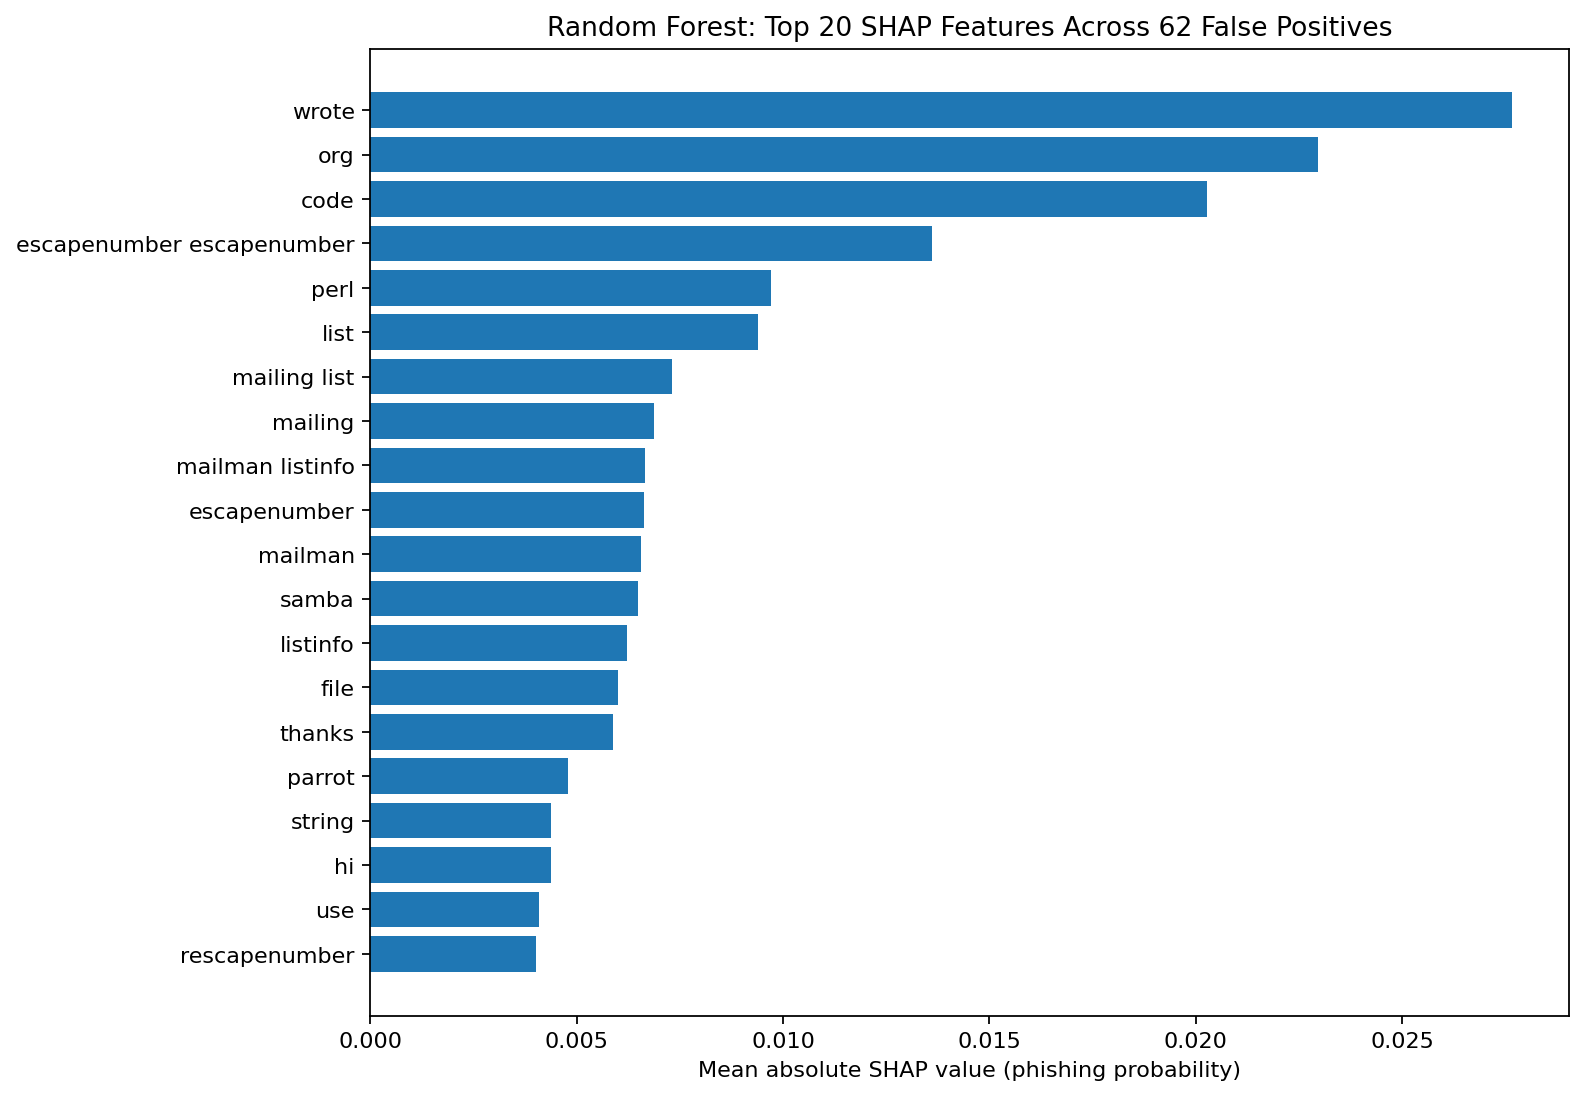

In [ ]:
# Recreate and save the original feature-importance feature-importance figure.
# Only the recorded feature-importance values are plotted; no new results are invented.
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(recorded_fp_top20['Feature'][::-1], recorded_fp_top20['Mean absolute SHAP'][::-1])
ax.set_xlabel('Mean absolute SHAP value (phishing probability)')
ax.set_title('Random Forest: Top 20 SHAP Features Across 62 False Positives')
fig.tight_layout()
fig.savefig('Random_Forest_Top20_SHAP_FP.png', dpi=300, bbox_inches='tight')
fig.savefig('Random_Forest_Top20_SHAP_FP.svg', bbox_inches='tight')
plt.show()
print('Saved: Random_Forest_Top20_SHAP_FP.png and Random_Forest_Top20_SHAP_FP.svg')


### Verification of feature rankings

The feature rankings are also calculated directly from the SHAP results. The five highest-ranked features are compared with the recorded values to check consistency with the original baseline model and background dataset.


In [ ]:
feature_names_rf = np.asarray(tfidf_vectorizer.get_feature_names_out())
fp_mean_abs_rf = np.abs(fp_shap_values_rf).mean(axis=0)
fp_mean_signed_rf = fp_shap_values_rf.mean(axis=0)
ranked_rf = np.argsort(fp_mean_abs_rf)[::-1]
computed_fp_top20 = pd.DataFrame({
    'Feature': feature_names_rf[ranked_rf[:20]],
    'Mean absolute SHAP': fp_mean_abs_rf[ranked_rf[:20]],
    'Mean signed SHAP': fp_mean_signed_rf[ranked_rf[:20]],
})
display(computed_fp_top20)
assert list(computed_fp_top20['Feature'][:5]) == list(recorded_fp_top20['Feature'][:5]), (
    'The first five features do not match the recorded feature-importance ranking. Check the locked baseline and SHAP background.'
)

## 5. Direction of SHAP contributions

Mean absolute SHAP values describe the magnitude of a feature's influence, whereas **mean signed SHAP values** indicate its average direction.

Positive values indicate contributions toward the phishing class; negative values indicate contributions toward the legitimate class. The following tables report selected findings from the original experiment.


In [ ]:
recorded_fp_toward_phishing = pd.DataFrame([
    {'Feature':'wrote','Mean signed SHAP':0.02333770},
    {'Feature':'org','Mean signed SHAP':0.02014730},
    {'Feature':'perl','Mean signed SHAP':0.00970759},
    {'Feature':'code','Mean signed SHAP':0.00757647},
    {'Feature':'mailing list','Mean signed SHAP':0.00732118},
])
recorded_fp_toward_legitimate = pd.DataFrame([
    {'Feature':'thanks','Mean signed SHAP':-0.00316245},
    {'Feature':'file','Mean signed SHAP':-0.00262233},
    {'Feature':'com www','Mean signed SHAP':-0.00245832},
    {'Feature':'release','Mean signed SHAP':-0.00211018},
])
print('Recorded features pushing FP predictions toward phishing:')
display(recorded_fp_toward_phishing.style.format({'Mean signed SHAP':'{:+.8f}'}))
print('Recorded features pushing FP predictions toward legitimate:')
display(recorded_fp_toward_legitimate.style.format({'Mean signed SHAP':'{:+.8f}'}))

Across the false-positive cases, features such as `wrote` and `org` had positive mean SHAP contributions, increasing the predicted phishing probability on average. In contrast, features such as `thanks` and `file` had negative mean contributions.

These are average effects across the analysed emails; the contribution of a feature may differ between individual messages. The following code calculates the complete feature rankings.


In [ ]:
signed_order_positive = np.argsort(fp_mean_signed_rf)[::-1]
signed_order_negative = np.argsort(fp_mean_signed_rf)
fp_toward_phishing = pd.DataFrame({'feature':feature_names_rf[signed_order_positive[:20]], 'mean_signed_shap':fp_mean_signed_rf[signed_order_positive[:20]]})
fp_toward_legitimate = pd.DataFrame({'feature':feature_names_rf[signed_order_negative[:20]], 'mean_signed_shap':fp_mean_signed_rf[signed_order_negative[:20]]})
print('Toward phishing:')
display(fp_toward_phishing)
print('Toward legitimate:')
display(fp_toward_legitimate)

## 6. False-negative SHAP analysis

False negatives occur when phishing emails are incorrectly classified as legitimate. The same saved Random Forest model and SHAP background are used to examine all **15 false-negative cases**.

This analysis investigates features associated with missed phishing emails without modifying the baseline model.


In [ ]:
fn_tfidf_rf = X_test_tfidf[false_negative_positions_rf]
fn_parts = []
for start in range(0, len(false_negative_positions_rf), 5):
    dense = fn_tfidf_rf[start:start+5].toarray()
    fn_parts.append(phishing_class_shap(explainer_rf.shap_values(dense, check_additivity=False)))
fn_shap_values_rf = np.vstack(fn_parts)
assert fn_shap_values_rf.shape == (15, 10000)
fn_reconstructed = expected_rf + fn_shap_values_rf.sum(axis=1)
fn_additivity_error = np.abs(fn_reconstructed - baseline_prob_rf[false_negative_positions_rf])
assert fn_additivity_error.max() < 1e-5
fn_mean_signed_rf = fn_shap_values_rf.mean(axis=0)
fn_toward_legitimate = pd.DataFrame({'feature':feature_names_rf[np.argsort(fn_mean_signed_rf)[:20]], 'mean_signed_shap':np.sort(fn_mean_signed_rf)[:20]})
fn_toward_phishing = pd.DataFrame({'feature':feature_names_rf[np.argsort(fn_mean_signed_rf)[::-1][:20]], 'mean_signed_shap':np.sort(fn_mean_signed_rf)[::-1][:20]})
print('FN maximum additivity error:', fn_additivity_error.max())
print('FN features toward legitimate:')
display(fn_toward_legitimate)
print('FN features toward phishing:')
display(fn_toward_phishing)

### Verification of false-negative explanations

| Verification measure | Recorded result |
|---|---:|
| False negatives explained | 15 |
| TF-IDF features | 10,000 |
| Maximum additivity error | 8.900361309072125e-09 |

The following tables present selected features from the original analysis. Negative SHAP contributions reduced the predicted phishing probability and therefore supported classification toward the legitimate class.


In [ ]:
recorded_fn_toward_legitimate = pd.DataFrame([
    ('wrote',-0.08755146),('cheers',-0.02313851),('code',-0.01851887),
    ('samba',-0.01431133),('jonathan',-0.00999678),('lib',-0.00965811),
    ('perl',-0.00915535),('debian',-0.00881763),
], columns=['Feature','Mean signed SHAP'])
recorded_fn_toward_phishing = pd.DataFrame([
    ('org',0.00570359),('mailing list',0.00312099),
], columns=['Feature','Mean signed SHAP'])
print('Recorded FN features pushing toward legitimate:')
display(recorded_fn_toward_legitimate.style.format({'Mean signed SHAP':'{:+.8f}'}))
print('Recorded FN features pushing toward phishing:')
display(recorded_fn_toward_phishing.style.format({'Mean signed SHAP':'{:+.8f}'}))

Among the 15 false-negative emails, `wrote` showed a substantial negative mean SHAP contribution. This finding is relevant to the study's objective: reducing false positives while avoiding an increase in false negatives.

The present notebook is limited to explaining baseline classification errors. It does not evaluate an updated classifier.


## 7. Summary of findings

| Analysis component | Recorded finding |
|---|---|
| Official baseline | 62 false positives and 15 false negatives |
| SHAP background | 100 training emails, with 50 from each class |
| False-positive analysis | SHAP explanations calculated for all 62 false-positive cases |
| Feature importance | Top 20 features reported in a table and horizontal bar chart |
| Feature direction | Positive and negative SHAP contributions examined separately |
| False-negative analysis | SHAP explanations calculated for all 15 false-negative cases |

The results identify features associated with incorrect predictions made by the baseline Random Forest model. This analysis provides the evidence used to guide the later counterfactual and model-improvement experiments. **No reduction in classification errors is claimed in this notebook.**

### Reproducing the analysis

This notebook can be run in Jupyter Notebook or Google Colab. First, run **RF 02 — Official Baseline** to generate the required model and data files. Make those checkpoint files available in the working environment, then execute the RF 03 cells in order. If the files are stored in another folder, set the `RF_BASELINE_DIR` environment variable to that folder.

The notebook verifies the baseline predictions and SHAP calculations against the recorded experimental results. The horizontal SHAP feature-importance chart is included for direct viewing on GitHub and can also be generated by running the plotting code. The numerical results are those recorded during the original experiment; this GitHub revision has not independently rerun the full analysis.
